In [4]:
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
import numpy as np
trajectories = np.load("data/nordic_trajectories.npy")

print(trajectories.shape)


(462, 49, 211, 211, 1)


In [3]:
indices = [0, 15, 30, 45]

fields = [
    trajectories[i, :, :, 0]
    for i in indices
]

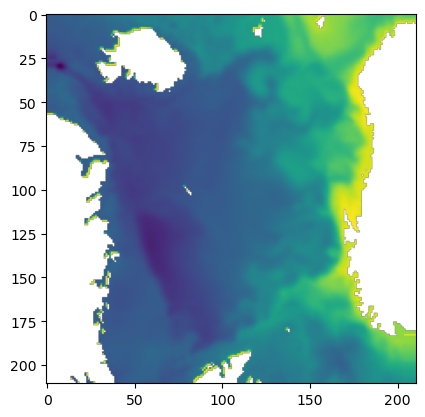

In [9]:
plt.imshow(trajectories[100,0,:,:,0])

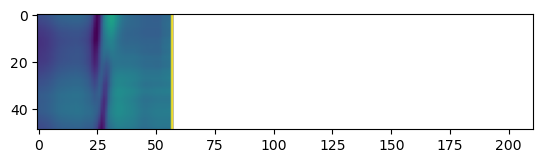

In [ ]:
plt.Figure()
plt.contourf(lon_2, lat_2, frame)
plt.colorbar(label='sea surface height (m)')



In [6]:
ds_ocean = xr.open_zarr("data/nemo_ocean.zarr")
print(ds_ocean.coords)
print(ds_ocean)
print(ds_ocean.data_vars)

Coordinates:
  * time         (time) datetime64[ns] 322kB 2020-06-01 ... 2024-12-31T23:00:00
  * y            (y) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
  * x            (x) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
    lat          (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    lon          (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    alpha_ref    int64 8B ...
    spatial_ref  int64 8B ...
<xarray.Dataset> Size: 7GB
Dimensions:       (time: 40200, y: 211, x: 211)
Coordinates:
  * time          (time) datetime64[ns] 322kB 2020-06-01 ... 2024-12-31T23:00:00
  * y             (y) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
  * x             (x) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
    lat           (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    lon           (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    alpha_ref     int6

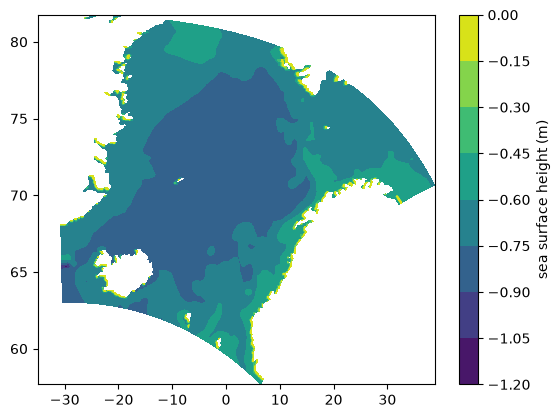

In [10]:
import torch
lat_2 = torch.tensor(ds_ocean['lat'].values, dtype=torch.float)
lon_2 = torch.tensor(ds_ocean['lon'].values, dtype=torch.float)

frame = ds_ocean["ssh"].isel(time=0).values


plt.Figure()
plt.contourf(lon_2, lat_2, frame)
plt.colorbar(label='sea surface height (m)')

In [11]:
ds_forcing = xr.open_zarr("data/nemo_forcing.zarr")
print(ds_forcing.coords)
print(ds_forcing)
print(ds_forcing.data_vars)

Coordinates:
  * time         (time) datetime64[ns] 322kB 2020-06-01 ... 2024-12-31T23:00:00
  * y            (y) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
  * x            (x) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
    lat          (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    lon          (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    alpha_ref    int64 8B ...
    spatial_ref  int64 8B ...
<xarray.Dataset> Size: 21GB
Dimensions:       (time: 40200, y: 211, x: 211)
Coordinates:
  * time          (time) datetime64[ns] 322kB 2020-06-01 ... 2024-12-31T23:00:00
  * y             (y) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
  * x             (x) float64 2kB -1.05e+06 -1.04e+06 ... 1.04e+06 1.05e+06
    lat           (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    lon           (y, x) float64 356kB dask.array<chunksize=(106, 211), meta=np.ndarray>
    alpha_ref     int

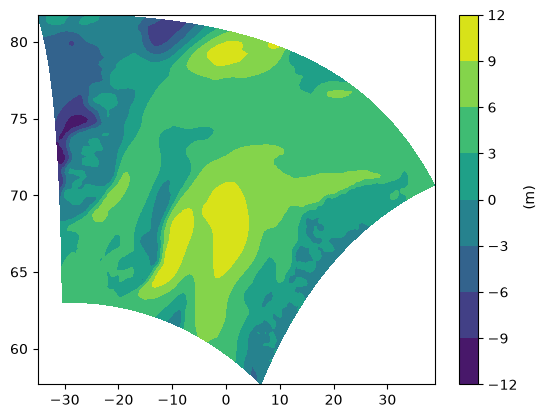

In [14]:
lat_2 = torch.tensor(ds_ocean['lat'].values, dtype=torch.float)
lon_2 = torch.tensor(ds_ocean['lon'].values, dtype=torch.float)

frame = ds_forcing["v10"].isel(time=0).values


plt.Figure()
plt.contourf(lon_2, lat_2, frame)
plt.colorbar(label=' (m)')